# המאפייה של דנה — מסיפור לגרף
תרגיל 2 בקורס סוכני AI. מערכת הזמנות דטרמיניסטית ב־Python ו־LangGraph, ללא LLM, ללא מפתח API.

יש להריץ את התאים לפי הסדר באמצעות Runtime → Run all. כל הזמנה מקבלת עותק של המלאי ההתחלתי; רק העותק מתעדכן בסיום הזמנה מאושרת.

## תכנון לפני המימוש
```mermaid
flowchart TD
    START --> validation
    validation -->|valid| inventory
    validation -->|invalid| message
    inventory -->|enough| pricing
    inventory -->|not enough| substitution
    substitution -->|next candidate, max 2| inventory
    substitution -->|no candidate or limit| message
    pricing --> delivery
    delivery --> message
    message --> final_processing
    final_processing --> END
```
לכל ניסיון החלפה חוזרים לבדיקת המלאי של המוצר החדש. דחייה מדלגת על תמחור ומשלוח, אך תמיד עוברת דרך הודעה וסיום.

## התקנה
הגרסה מקובעת לגרסה שנבדקה. חיבור לרשת נדרש להתקנת החבילות ולציור בלבד; חישוב ההזמנות אינו משתמש ברשת.

In [1]:
%pip install -q "langgraph==1.2.20" "langchain-core==1.7.6"

Note: you may need to restart the kernel to use updated packages.


C:\Users\liat1\Desktop\לימודים\שנה ד\סמסטר א\סוכני AI\LangGraph\תרגיל 2\.venv\Scripts\python.exe: No module named pip


## מוצרים, מלאי והגדרת מצב
המחירים בשקלים. יום חייב להיות שם יום תקין באנגלית; הכמות חייבת להיות מספר שלם חיובי, וערכי bool אינם כמות. עיר חסרה, None או רווחים בלבד פירושם איסוף עצמי. עיר שאינה טקסט נדחית כקלט לא תקין; כל עיר תקינה מחוץ לירושלים מומרת לאיסוף.

In [2]:
"""המאפייה של דנה — מימוש דטרמיניסטי ללא מודל שפה."""
from decimal import Decimal
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

PRICES = {"challah": 18, "babka": 45, "rugelach": 30, "sourdough": 25}
INITIAL_STOCK = {"challah": 10, "babka": 0, "rugelach": 3, "sourdough": 4}
SUBSTITUTES = {"babka": "rugelach", "rugelach": "sourdough", "sourdough": "challah"}
DAYS = {"Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"}


class OrderState(TypedDict, total=False):
    item: str | None
    quantity: int
    day: str
    city: str
    requested_item: str
    stock: dict[str, int]
    attempts: int
    available: bool
    status: str
    reason: str
    subtotal: float
    discount: float
    delivery_fee: int
    delivery: str
    total: float
    message: str
    steps: list[str]




## צמתים וניתוב
שבעה צמתים נפרדים. הרשימה steps שומרת את סדר הפעולות. השדה item מכיל את המועמד הנוכחי במהלך החיפוש, ובסיום רק מוצר שנמכר או None.

ההנחה היא 15% רק מעל 150 ₪ ולא ביום שישי. Decimal מונע שגיאות חישוב כספיות; דמי משלוח מתווספים לאחר ההנחה.

In [3]:
def log(state, text):
    # יוצרים רשימה חדשה כדי לא לשנות את המצב הקודם במקום.
    return state["steps"] + [text]


def validate_order(state):
    item, quantity, day = state.get("item"), state.get("quantity"), state.get("day")
    city = state.get("city", "")
    errors = []
    if not isinstance(item, str) or item not in PRICES:
        errors.append("המוצר אינו בתפריט; קרואסונים אינם נמכרים עוד")
    if type(quantity) is not int or quantity <= 0:
        errors.append("הכמות חייבת להיות מספר שלם חיובי")
    if not isinstance(day, str) or day not in DAYS:
        errors.append("יש להזין יום תקין באנגלית, למשל Thursday")
    if city is None:
        city = ""
    if not isinstance(city, str):
        errors.append("העיר חייבת להיות טקסט או ריקה")
    else:
        city = city.strip()
    # כל הפעלה מתחילה מחדש: אין מלאי משותף או זיכרון בין הזמנות.
    return {"requested_item": item, "city": city, "stock": INITIAL_STOCK.copy(),
            "attempts": 0, "available": False, "status": "rejected" if errors else "accepted",
            "reason": "; ".join(errors), "subtotal": 0, "discount": 0,
            "delivery_fee": 0, "delivery": "pickup", "total": 0, "message": "",
            "steps": ["אימות קלט: " + ("; ".join(errors) if errors else "תקין")]}


def check_inventory(state):
    item = state["item"]
    enough = state["stock"][item] >= state["quantity"]
    return {"available": enough,
            "steps": log(state, f"בדיקת מלאי: {item}, נדרשו {state['quantity']}, קיימים {state['stock'][item]} — {'מספיק' if enough else 'לא מספיק'}")}


def substitute(state):
    item = state["item"]
    if state["attempts"] >= 2:
        reason = "שני ניסיונות ההחלפה נכשלו"
    elif item not in SUBSTITUTES:
        reason = "אין חלופה מוגדרת לחלה"
    else:
        alternative = SUBSTITUTES[item]
        attempt = state["attempts"] + 1
        return {"item": alternative, "attempts": attempt,
                "steps": log(state, f"ניסיון החלפה {attempt}: {item} ← {alternative}; הכמות נשארת {state['quantity']}")}
    return {"status": "rejected", "reason": reason, "steps": log(state, reason)}


def price_order(state):
    subtotal = Decimal(PRICES[state["item"]]) * state["quantity"]
    # הסף מחמיר: 150 בדיוק אינו מזכה בהנחה. דמי משלוח מחושבים בנפרד.
    discount = (subtotal * Decimal("0.15")) if subtotal > 150 and state["day"] != "Friday" else Decimal(0)
    total = subtotal - discount
    return {"subtotal": float(subtotal), "discount": float(discount), "total": float(total),
            "steps": log(state, f"תמחור: סכום מוצרים {subtotal} ₪, הנחה {discount} ₪, לאחר הנחה {total} ₪")}


def decide_delivery(state):
    if state["city"].casefold() == "jerusalem":
        delivery, fee, text = "delivery", 20, "משלוח בירושלים: 20 ₪"
    elif not state["city"]:
        delivery, fee, text = "pickup", 0, "עיר ריקה: איסוף עצמי ללא תשלום"
    else:
        delivery, fee, text = "pickup", 0, f"אין משלוח אל {state['city']}: הועבר לאיסוף עצמי ללא תשלום"
    return {"delivery": delivery, "delivery_fee": fee, "total": state["total"] + fee,
            "steps": log(state, text)}


def customer_message(state):
    if state["status"] == "rejected":
        message = f"שלום מהמאפייה של דנה! לצערנו לא ניתן להשלים את הזמנתך: {state['reason']}. נשמח להזמנה חדשה."
    else:
        parts = [f"שלום מהמאפייה של דנה! הזמנתך ל־{state['quantity']} יחידות {state['item']} אושרה ליום {state['day']}."]
        if state["attempts"]:
            parts.append(f"עקב חוסר במלאי, {state['requested_item']} הוחלף ב־{state['item']} באותה כמות, לאחר {state['attempts']} ניסיונות החלפה.")
        if state["discount"]:
            parts.append(f"קיבלת הנחה של 15% על המוצרים בלבד: {state['discount']:.2f} ₪.")
        elif state["day"] == "Friday":
            parts.append("ביום שישי לא ניתנת הנחה.")
        if state["delivery"] == "delivery":
            parts.append("משלוח לירושלים בתוספת 20 ₪.")
        elif state["city"]:
            parts.append(f"אין משלוח אל {state['city']}; הזמנתך הועברה לאיסוף עצמי ללא תשלום.")
        else:
            parts.append("הזמנתך ממתינה לאיסוף עצמי ללא תשלום.")
        parts.append(f"סך הכול לתשלום: {state['total']:.2f} ₪. תודה ולהתראות!")
        message = " ".join(parts)
    return {"message": message, "steps": log(state, "נוצרה הודעה ללקוח")}


def finalize_order(state):
    updates = {}
    if state["status"] == "accepted":
        stock = state["stock"].copy()
        stock[state["item"]] -= state["quantity"]
        updates["stock"] = stock
    else:
        updates.update(item=None, total=0, delivery="pickup", delivery_fee=0)
    return {**updates, "steps": log(state, f"סטטוס סופי: {state['status']}")}


def after_validation(state):
    return "message" if state["status"] == "rejected" else "inventory"


def after_inventory(state):
    return "pricing" if state["available"] else "substitution"


def after_substitution(state):
    return "message" if state["status"] == "rejected" else "inventory"




## חיבור וקימפול הגרף
שלושה נתבים מחליטים על מסלול האימות, המלאי וההחלפה.

In [4]:
builder = StateGraph(OrderState)
for name, node in [("validation", validate_order), ("inventory", check_inventory),
                   ("substitution", substitute), ("pricing", price_order),
                   ("delivery", decide_delivery), ("message", customer_message),
                   ("final_processing", finalize_order)]:
    builder.add_node(name, node)
builder.add_edge(START, "validation")
builder.add_conditional_edges("validation", after_validation, {"message": "message", "inventory": "inventory"})
builder.add_conditional_edges("inventory", after_inventory, {"pricing": "pricing", "substitution": "substitution"})
builder.add_conditional_edges("substitution", after_substitution, {"message": "message", "inventory": "inventory"})
builder.add_edge("pricing", "delivery")
builder.add_edge("delivery", "message")
builder.add_edge("message", "final_processing")
builder.add_edge("final_processing", END)
graph = builder.compile()


## הצגת הגרף
הקריאה draw_mermaid_png() משתמשת בשירות Mermaid.ink לציור התרשים בלבד. נשלח מבנה הגרף, ללא פרטי הזמנות. אין שימוש בשירות AI. אם שירות הציור אינו זמין, יש להריץ שוב את התא לאחר חידוש החיבור.

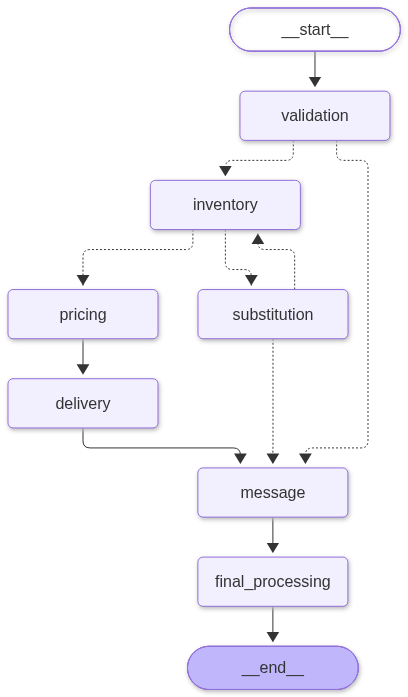

In [5]:
from IPython.display import Image, display
mermaid_png = graph.get_graph().draw_mermaid_png()
assert mermaid_png.startswith(b"\x89PNG\r\n\x1a\n")
display(Image(mermaid_png))

## הזמנה לדוגמה
הבקשה המקורית ל־2 babka מוחלפת ב־2 rugelach: מחיר המוצרים 60 ₪ ומשלוח 20 ₪.

In [6]:
result = graph.invoke({
    "item": "babka",
    "quantity": 2,
    "day": "Thursday",
    "city": "Jerusalem"
})
for key in ["status", "item", "delivery", "total", "message", "steps"]:
    print(f"{key}: {result[key]}")

status: accepted
item: rugelach
delivery: delivery
total: 80.0
message: שלום מהמאפייה של דנה! הזמנתך ל־2 יחידות rugelach אושרה ליום Thursday. עקב חוסר במלאי, babka הוחלף ב־rugelach באותה כמות, לאחר 1 ניסיונות החלפה. משלוח לירושלים בתוספת 20 ₪. סך הכול לתשלום: 80.00 ₪. תודה ולהתראות!
steps: ['אימות קלט: תקין', 'בדיקת מלאי: babka, נדרשו 2, קיימים 0 — לא מספיק', 'ניסיון החלפה 1: babka ← rugelach; הכמות נשארת 2', 'בדיקת מלאי: rugelach, נדרשו 2, קיימים 3 — מספיק', 'תמחור: סכום מוצרים 60 ₪, הנחה 0 ₪, לאחר הנחה 60 ₪', 'משלוח בירושלים: 20 ₪', 'נוצרה הודעה ללקוח', 'סטטוס סופי: accepted']


## בדיקות ותוצאות צפויות
CASES מפרטת במפורש מוצר, ניסיונות החלפה, משלוח וסכום צפויים. הבדיקות כוללות קלט שגוי, החלפות, דחיות, הנחות ושלוש החלטות משלוח. בנוסף נבדקים כל המוצרים, כמויות 1–11, שבעת הימים ושלוש אפשרויות משלוח. כמות מעל 11 יוצרת אותו מסלול דחייה כמו 11.

במלאי הנתון אי אפשר להגיע לסכום מוצרים של 150 ₪ בדיוק: rugelach מוגבל ל־90, sourdough ל־100, וחלה נמכרת בכפולות 18. לכן נבדקים הגבולות האפשריים 144 ו־162; הקוד עצמו משתמש בהשוואה מחמירה > 150.

הפעלת אותה הזמנה פעמיים בודקת דטרמיניזם ואי־תלות בין הזמנות.

In [7]:
"""בדיקות עם תוצאות צפויות וחישוב עצמאי של כללי העסק."""

REQUIRED = {"status", "item", "delivery", "total", "message", "steps"}
# שם, קלט, מוצר צפוי, מספר החלפות, משלוח, סכום צפוי
CASES = [
    ("מלאי ומשלוח", dict(item="challah", quantity=2, day="Thursday", city="Jerusalem"), "challah", 0, "delivery", 56),
    ("החלפה אחת", dict(item="babka", quantity=2, day="Thursday", city="Jerusalem"), "rugelach", 1, "delivery", 80),
    ("שתי החלפות", dict(item="babka", quantity=4, day="Monday", city="Haifa"), "sourdough", 2, "pickup", 100),
    ("כשל אחרי שתי החלפות", dict(item="babka", quantity=5, day="Monday", city=""), None, 2, "pickup", 0),
    ("קרואסון הופסק", dict(item="croissant", quantity=1, day="Monday", city=""), None, 0, "pickup", 0),
    ("הנחת 15 אחוז", dict(item="challah", quantity=10, day="Thursday", city="Jerusalem"), "challah", 0, "delivery", 173),
    ("שישי ללא הנחה", dict(item="challah", quantity=10, day="Friday", city=""), "challah", 0, "pickup", 180),
    ("עיר חסרה", dict(item="sourdough", quantity=1, day="Sunday"), "sourdough", 0, "pickup", 25),
    ("חלה חסרה ללא חלופה", dict(item="challah", quantity=11, day="Monday", city=""), None, 0, "pickup", 0),
    ("החלפה שנייה לחלה", dict(item="rugelach", quantity=5, day="Tuesday", city=""), "challah", 2, "pickup", 90),
    ("החלפה לחלה ואז כשל", dict(item="sourdough", quantity=11, day="Tuesday", city=""), None, 1, "pickup", 0),
    ("חלופה ראשונה לחלה", dict(item="sourdough", quantity=5, day="Tuesday", city=""), "challah", 1, "pickup", 90),
    ("גבול מתחת להנחה", dict(item="challah", quantity=8, day="Thursday", city=""), "challah", 0, "pickup", 144),
    ("מעל סף ההנחה", dict(item="challah", quantity=9, day="Thursday", city=""), "challah", 0, "pickup", 137.7),
]
for field, value in [("quantity", 0), ("quantity", -1), ("quantity", 1.5),
                     ("quantity", True), ("quantity", "2"), ("day", "Funday"),
                     ("day", None), ("city", 123), ("item", []), ("item", "unknown")]:
    order = dict(item="challah", quantity=1, day="Monday", city="")
    order[field] = value
    CASES.append((f"קלט לא תקין: {field}={value}", order, None, 0, "pickup", 0))
for field in ["item", "quantity", "day"]:
    order = dict(item="challah", quantity=1, day="Monday", city="")
    del order[field]
    CASES.append((f"שדה חסר: {field}", order, None, 0, "pickup", 0))
CASES.append(("עיר None", dict(item="challah", quantity=1, day="Monday", city=None), "challah", 0, "pickup", 18))


def check_contract(result):
    assert REQUIRED <= result.keys()
    assert result["status"] in {"accepted", "rejected"}
    assert result["delivery"] in {"pickup", "delivery"}
    assert isinstance(result["message"], str) and result["message"]
    assert isinstance(result["steps"], list) and all(isinstance(s, str) for s in result["steps"])
    assert result["steps"][0].startswith("אימות קלט")
    assert result["steps"][-1] == f"סטטוס סופי: {result['status']}"
    assert result["attempts"] <= 2
    if result["status"] == "rejected":
        assert result["item"] is None and result["total"] == 0
        assert result["stock"] == INITIAL_STOCK


def run_tests():
    for name, order, item, attempts, delivery, total in CASES:
        result = graph.invoke(order)
        check_contract(result)
        assert result["status"] == ("accepted" if item else "rejected"), name
        assert (result["item"], result["attempts"], result["delivery"]) == (item, attempts, delivery), name
        assert abs(result["total"] - total) < 1e-9, name
        assert result == graph.invoke(order), f"חוסר דטרמיניזם: {name}"
        if item:
            assert result["quantity"] == order["quantity"]
            assert result["stock"][item] == INITIAL_STOCK[item] - order["quantity"]
        print(f"PASS: {name}")

    # כל נתיבי המלאי האפשריים במלאי הקבוע: כמות מעל 11 מתנהגת כמו 11.
    # מאמתים מול חישוב עצמאי, בלי לקרוא לפונקציות הצמתים.
    prices = {"challah": 18, "babka": 45, "rugelach": 30, "sourdough": 25}
    chains = {"babka": ["babka", "rugelach", "sourdough"],
              "rugelach": ["rugelach", "sourdough", "challah"],
              "sourdough": ["sourdough", "challah"], "challah": ["challah"]}
    exhaustive = 0
    for requested, chain in chains.items():
        for quantity in range(1, 12):
            for day in ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]:
                for city in ["", "Jerusalem", "Tel Aviv"]:
                    order = dict(item=requested, quantity=quantity, day=day, city=city)
                    result = graph.invoke(order)
                    check_contract(result)
                    sold = next((p for p in chain if INITIAL_STOCK[p] >= quantity), None)
                    expected = 0
                    if sold:
                        subtotal = prices[sold] * quantity
                        expected = round(subtotal * (0.85 if subtotal > 150 and day != "Friday" else 1), 2)
                        expected += 20 if city == "Jerusalem" else 0
                        assert result["delivery"] == ("delivery" if city == "Jerusalem" else "pickup")
                        assert result["attempts"] == chain.index(sold)
                        assert result["quantity"] == quantity
                        if city == "Tel Aviv":
                            assert "הועברה לאיסוף עצמי" in result["message"]
                        if result["discount"]:
                            assert "15%" in result["message"]
                        if result["attempts"]:
                            assert "הוחלף" in result["message"]
                    assert result["item"] == sold
                    assert result["status"] == ("accepted" if sold else "rejected")
                    assert abs(result["total"] - expected) < 1e-9
                    exhaustive += 1
    assert INITIAL_STOCK == {"challah": 10, "babka": 0, "rugelach": 3, "sourdough": 4}
    print(f"All {len(CASES) + exhaustive} tests passed ({len(CASES)} named + {exhaustive} combinations).")
    return len(CASES) + exhaustive


passed = run_tests()


PASS: מלאי ומשלוח
PASS: החלפה אחת
PASS: שתי החלפות
PASS: כשל אחרי שתי החלפות
PASS: קרואסון הופסק
PASS: הנחת 15 אחוז
PASS: שישי ללא הנחה
PASS: עיר חסרה
PASS: חלה חסרה ללא חלופה
PASS: החלפה שנייה לחלה
PASS: החלפה לחלה ואז כשל
PASS: חלופה ראשונה לחלה
PASS: גבול מתחת להנחה
PASS: מעל סף ההנחה
PASS: קלט לא תקין: quantity=0
PASS: קלט לא תקין: quantity=-1
PASS: קלט לא תקין: quantity=1.5
PASS: קלט לא תקין: quantity=True
PASS: קלט לא תקין: quantity=2
PASS: קלט לא תקין: day=Funday
PASS: קלט לא תקין: day=None
PASS: קלט לא תקין: city=123
PASS: קלט לא תקין: item=[]
PASS: קלט לא תקין: item=unknown
PASS: שדה חסר: item
PASS: שדה חסר: quantity
PASS: שדה חסר: day
PASS: עיר None


All 952 tests passed (28 named + 924 combinations).
